#### Load all data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent


collision_df = pd.read_csv(PROJECT_ROOT / 'data/raw_data/collision_raw.csv', low_memory=False)
vehicle_df = pd.read_csv(PROJECT_ROOT / 'data/raw_data/vehicle_raw.csv', low_memory=False)

In [2]:
collision_df = collision_df[collision_df["collision_year"] <= 2024]
vehicle_df = vehicle_df[vehicle_df["collision_year"] <= 2024]

unite_missing_category_collision_columns = [("speed_limit", 99), ("junction_detail_historic", 99),
                                            ("road_type", 9), ("speed_limit", 99),
                                            ("junction_detail", 99), ("junction_control", 9),
                                            ("second_road_class", 9), ("pedestrian_crossing", 99),
                                            ("weather_conditions", 9), ("road_surface_conditions", 9),
                                            ("carriageway_hazards_historic", 9), ("special_conditions_at_site", 9)]
unite_missing_category_vehicle_columns = [("vehicle_manoeuvre", 99), ("vehicle_location_restricted_lane_historic", 99),
                                         ("junction_location", 9), ("skidding_and_overturning", 9),
                                         ("hit_object_in_carriageway", 99), ("vehicle_leaving_carriageway", 9),
                                         ("hit_object_off_carriageway", 99), ("first_point_of_impact", 9)]

for column, n in unite_missing_category_collision_columns:
    collision_df[column] .map((lambda x: -1 if x==n else x))

for column, n in unite_missing_category_vehicle_columns:
    vehicle_df[column] .map((lambda x: -1 if x==n else x))

#### Remove test data (year 2025) and make sure that each column has just one category for missing values

#### Location data

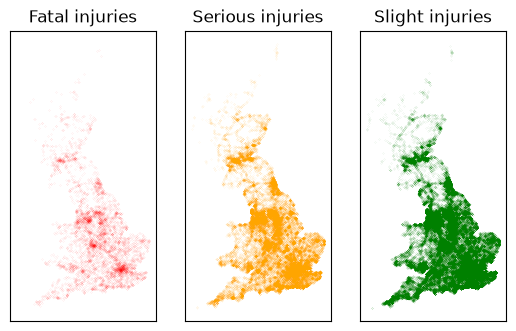

In [3]:
fig, axes = plt.subplots(nrows=1, ncols=3, sharex=True, sharey=True)


collision_df[collision_df["collision_severity"]==1].plot(kind="scatter", x="location_easting_osgr", 
                                                         y="location_northing_osgr", grid=True, alpha = 0.3, 
                                                         s=0.01, c="red", ax = axes[0])
collision_df[collision_df["collision_severity"]==2].plot(kind="scatter", x="location_easting_osgr", 
                                                         y="location_northing_osgr", grid=True, alpha = 0.3, 
                                                         s=0.01, c="orange", ax = axes[1])
collision_df[collision_df["collision_severity"]==3].plot(kind="scatter", x="location_easting_osgr", 
                                                         y="location_northing_osgr", grid=True, alpha = 0.3, 
                                                         s=0.01, c="green", ax = axes[2])

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.tick_params(which="both", left=False)

axes[0].set_title("Fatal injuries")
axes[1].set_title("Serious injuries")
axes[2].set_title("Slight injuries")

plt.savefig(PROJECT_ROOT / 'outputs/figures/location_data.png', bbox_inches="tight")
plt.show()


##### This location data, aswell as the columns containing district codes, are not ideal to use, though a KNN style approach could be considered later to make use of it. To still include some location data, the police_force column will be used as it has less than 50 values and determines the local police force associated with the collision.

In [4]:
def graph_severity_wrt_categorical_column(column_name, df_name = "collision_df", vehicle_view=False, save_fig=None):
    collision_df = globals()[df_name]

    categories = sorted(collision_df[column_name].unique().tolist())

    df = np.array(categories).reshape(-1,1)
    data_len = len(categories)
    dict_names = {} 
    for i in range(data_len):
        dict_names.update({categories[i] : i})

    graph_data = pd.DataFrame(np.hstack( (df, np.zeros((data_len,3))) ))

    for i in range(1,4):
        for name, count in collision_df[collision_df["collision_severity"]==i][column_name].value_counts().items():
            graph_data.iloc[dict_names[name],i] = count

    graph_data[0] = graph_data[0].astype(int)

    graph_data["Total_percentage"] = graph_data[[1,2,3]].sum(axis=1) / graph_data.to_numpy().sum() * 100

    graph_data[[1,2,3]] = graph_data[[1,2,3]].div(graph_data[[1,2,3]].sum(axis=1), axis=0) * 100

    graph_data.rename(columns={0: f"Column {column_name}", 1 : "Fatal", 2 : "Serious", 3 : "Slight"}, inplace=True)

    graph_data.set_index(f"Column {column_name}", inplace=True)

    fig, ax = plt.subplots()
    graph_data.drop("Total_percentage", axis=1).plot(kind="bar", stacked=True, 
                                                     ylabel="Percantages of severities (bar)", ax=ax)
    ax.legend(loc="upper right")

    ax_total = ax.twinx()
    ax_total.plot(range(data_len), graph_data["Total_percentage"], marker="o", linestyle="", color="red")
    if vehicle_view:
        ax_total.set_ylabel("Percantage of overall vehicles (point)")
    else:
        ax_total.set_ylabel("Percantage of overall collisions (point)")
    ax_total.set_ylim(bottom=1/2 * graph_data["Total_percentage"].min(axis=0), top=4/3 * graph_data["Total_percentage"].max(axis=0))

    if save_fig != None or column_name in ["speed_limit", "carriageway_hazards_historic"]:
        plt.savefig(PROJECT_ROOT / ("outputs/figures/" + column_name + ".png"))

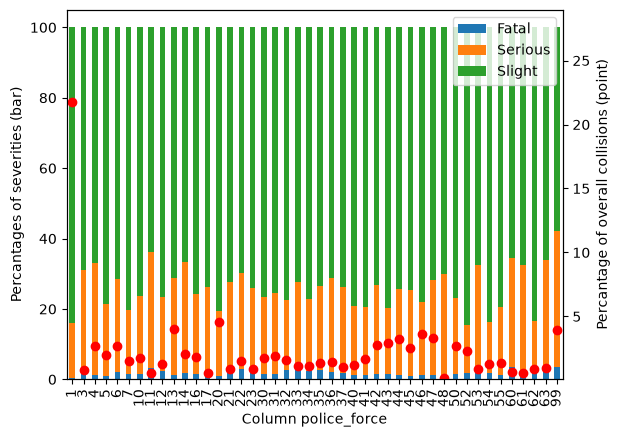

In [5]:
graph_severity_wrt_categorical_column("police_force")

#### Date and time data

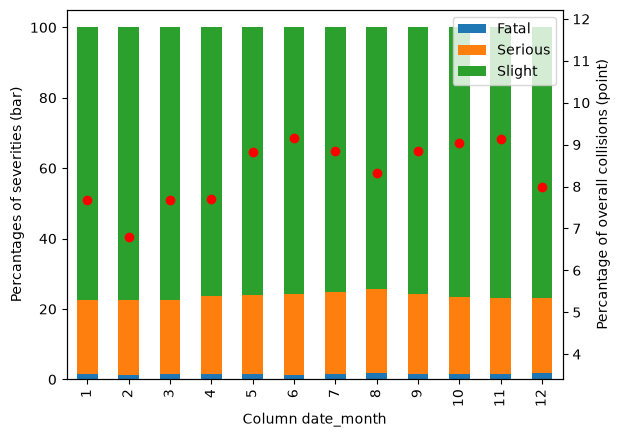

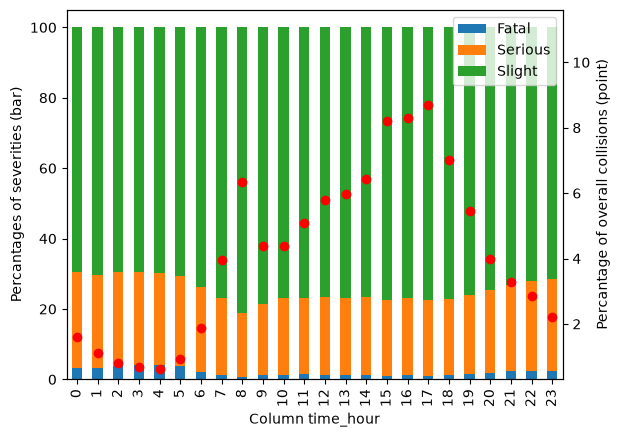

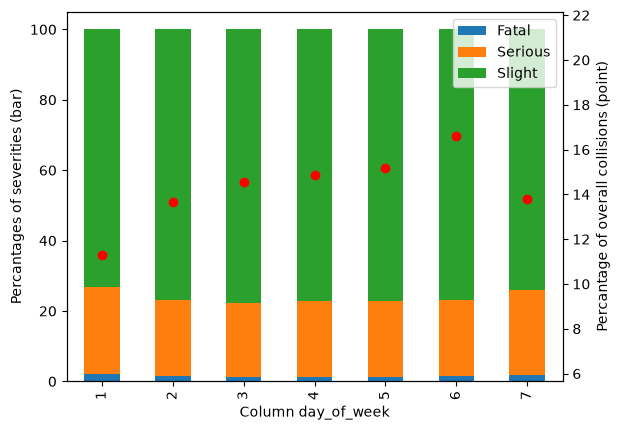

In [6]:
collision_df["date_month"] = pd.to_datetime(collision_df["date"], dayfirst=True).dt.month

graph_severity_wrt_categorical_column("date_month")

collision_df["time_hour"] = pd.to_datetime(collision_df["time"], format="%H:%M").dt.hour

graph_severity_wrt_categorical_column("time_hour")

graph_severity_wrt_categorical_column("day_of_week")

#### Road information

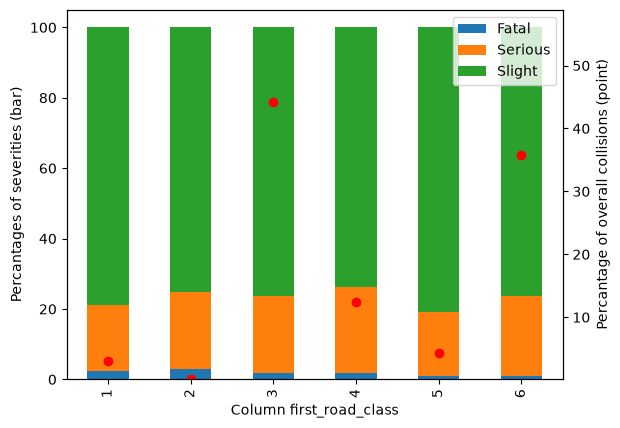

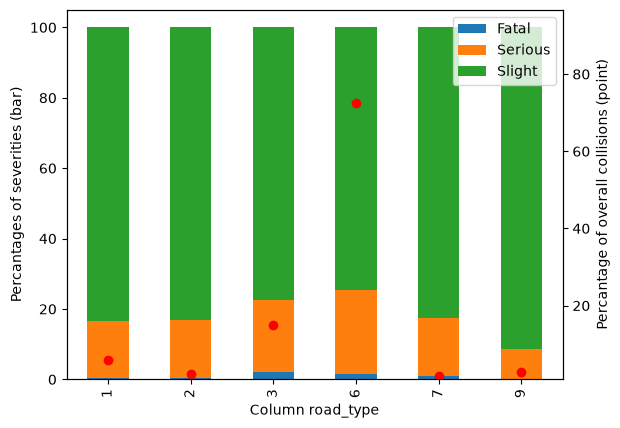

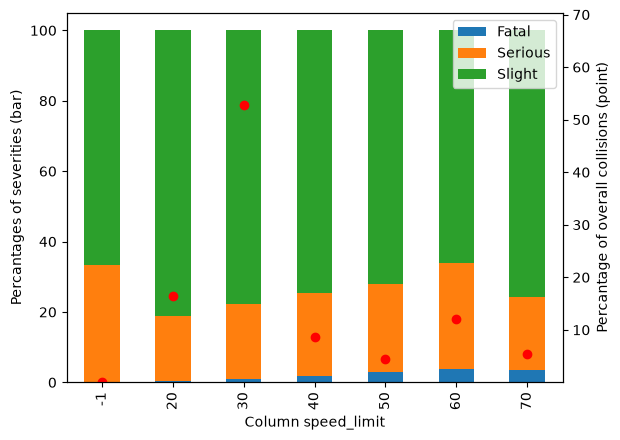

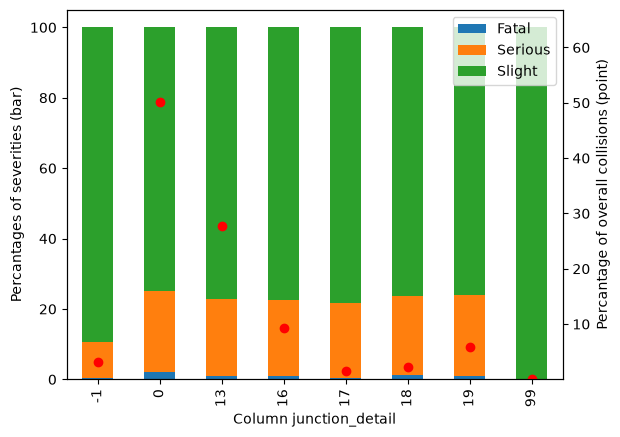

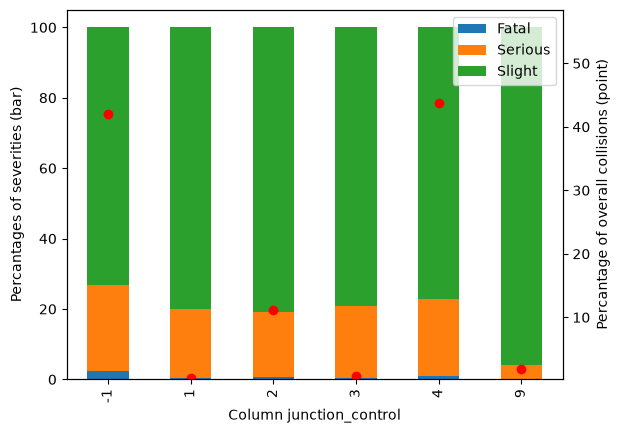

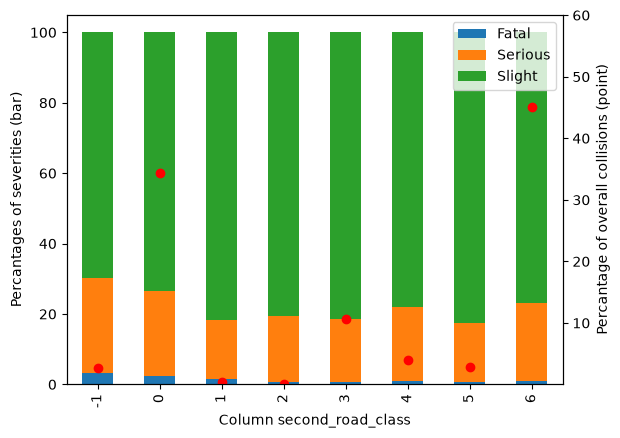

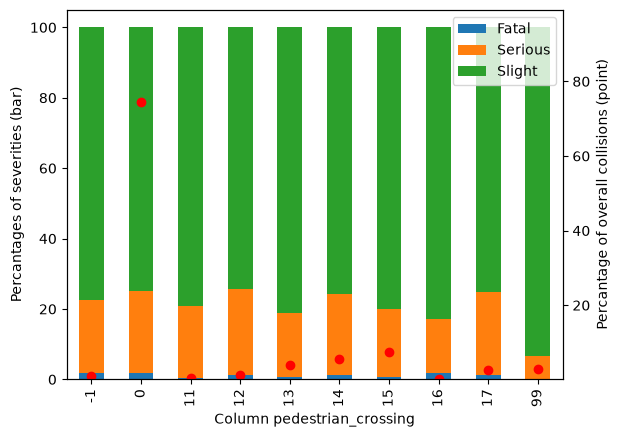

In [7]:
columns = ["first_road_class", "road_type", "speed_limit", "junction_detail", "junction_control", 
           "second_road_class", "pedestrian_crossing"]

for column in columns:
    graph_severity_wrt_categorical_column(column)

#### Enviroment

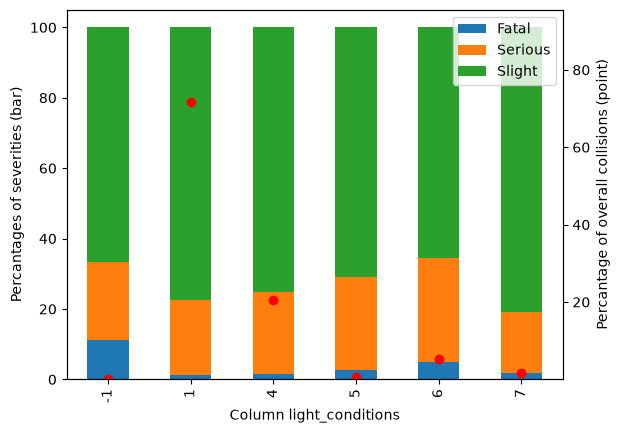

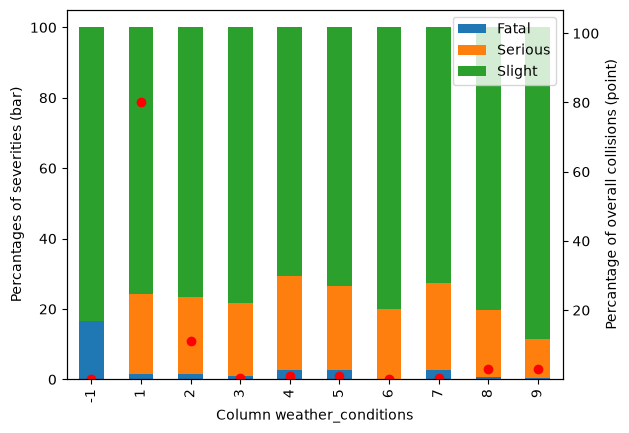

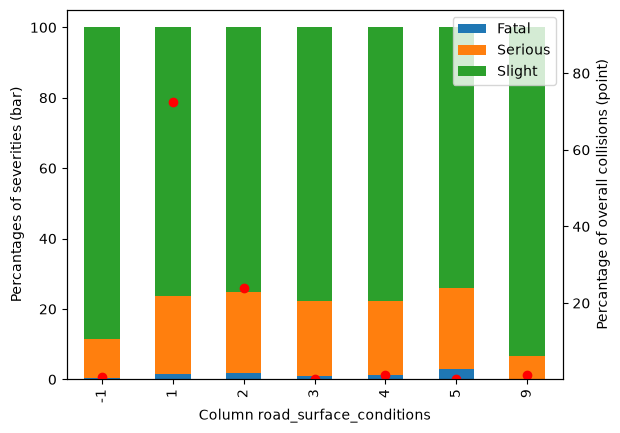

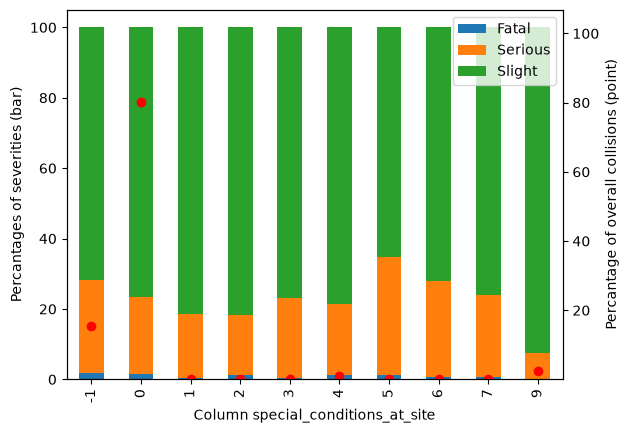

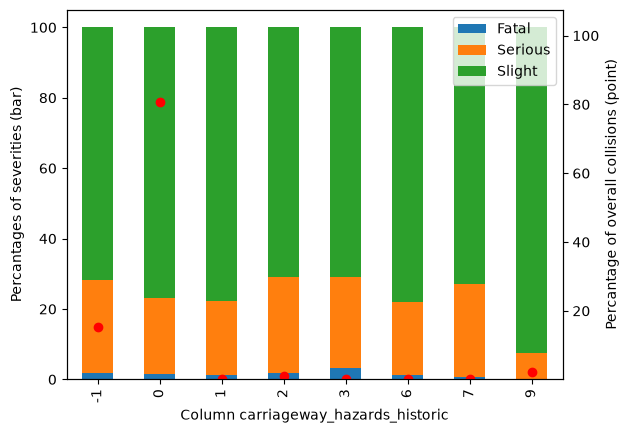

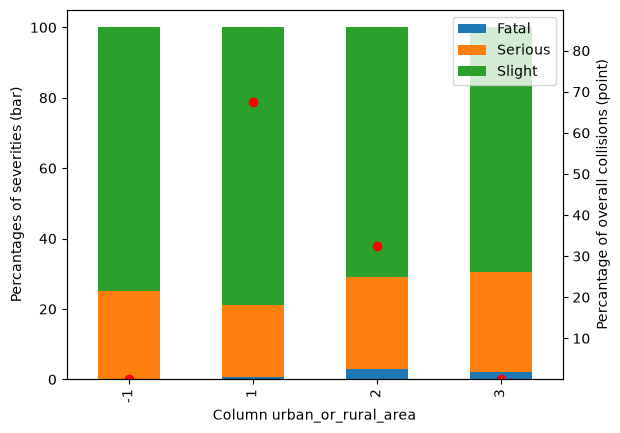

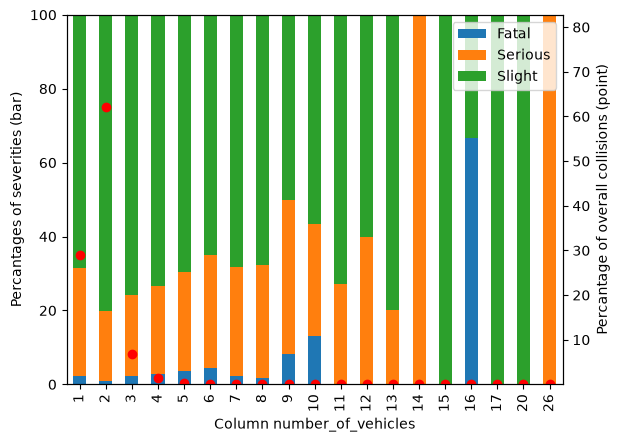

In [8]:
columns = ["light_conditions", "weather_conditions", "road_surface_conditions", "special_conditions_at_site", 
           "carriageway_hazards_historic", "urban_or_rural_area", "number_of_vehicles"]

for column in columns:
    graph_severity_wrt_categorical_column(column)

##### The columns pedestrian_crossing, special_conditions_at_site and cariageway_hazards_historic provide nongeneral information only very rarely and thus they will not be considered during the feature selection.

#### Selected bivariate analysis

In [9]:
def graph_bivariate(column_name1, column_name2, df_name="collision_df", save_fig=None):
    collision_df_binary_severity = globals()[df_name].copy()
    change_of_collision_severity = {1 : 1, 2 : 1, 3 : 0}
    collision_df_binary_severity["collision_severity"] = collision_df_binary_severity["collision_severity"].map(change_of_collision_severity)

    categories1 = sorted(collision_df_binary_severity[column_name1].unique().tolist())
    categories2 = sorted(collision_df_binary_severity[column_name2].unique().tolist())

    data_len1 = len(categories1)
    dict1 = {} 
    for i in range(data_len1):
        dict1.update({categories1[i] : i})

    data_len2 = len(categories2)
    dict2 = {} 
    for i in range(data_len2):
        dict2.update({categories2[i] : i})

    graph_data_severe = pd.DataFrame(np.zeros((data_len1,data_len2)))
    graph_data_all = pd.DataFrame(np.zeros((data_len1,data_len2)))

    for name, count in collision_df_binary_severity.groupby([column_name1, column_name2])[[column_name1,column_name2,"collision_severity"]].value_counts().items():
        graph_data_all.iloc[dict1[name[0]], dict2[name[1]]] += count
        if name[2]:
            graph_data_severe.iloc[dict1[name[0]], dict2[name[1]]] = count


    graph_data_severe = graph_data_severe.div(graph_data_all) * 100

    graph_data_sizes = graph_data_all.apply(lambda x: np.log(x+1))

    min_size, max_size, min_log, max_log = 0, 500, graph_data_sizes.to_numpy().min(), graph_data_sizes.to_numpy().max()

    graph_data_sizes = min_size + (max_size - min_size) * (graph_data_sizes - min_log) / (max_log - min_log)


    fig, ax = plt.subplots(figsize=(2+data_len1*0.5, 2+data_len2*0.5))

    graph_coordinates_x, graph_coordinates_y = np.meshgrid(np.arange(data_len1),np.arange(data_len2), indexing="ij")
    graph_data = pd.DataFrame({'x': graph_coordinates_x.ravel(), 'y': graph_coordinates_y.ravel(), 
                               "color": graph_data_severe.to_numpy().ravel(), "size": graph_data_sizes.to_numpy().ravel()})
    
    graph_data.plot.scatter(x='x', y='y', s="size", colormap="viridis", c="color", grid=True, ax=ax)

    ax.set_xlabel(column_name1)
    ax.set_ylabel(column_name2)
    ax.set_xticks(np.arange(data_len1))
    ax.set_xticklabels(categories1)
    ax.set_yticks(np.arange(data_len2))
    ax.set_yticklabels(categories2)
    ax.set_aspect("equal")

    colorbar = ax.collections[0].colorbar
    colorbar.set_label("Percentage of severe collisions")
    
    if save_fig != None or (column_name1, column_name2) in [("time_hour", "day_of_week")]:
        plt.savefig(PROJECT_ROOT / ("outputs/figures/" + column_name1 + "_x_" + column_name2 + ".png"), bbox_inches="tight")

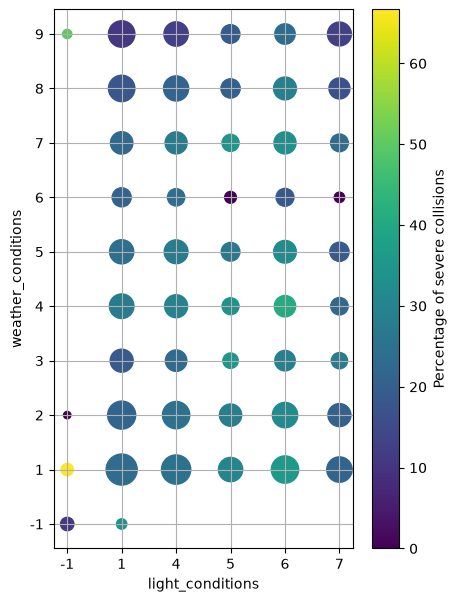

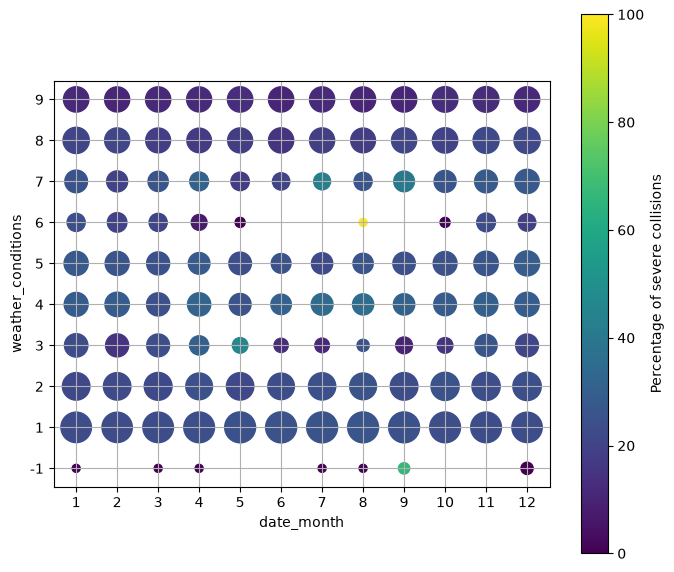

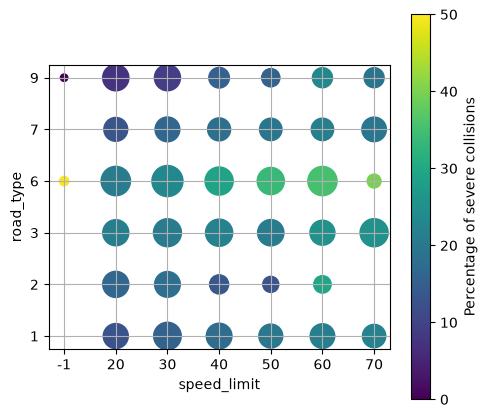

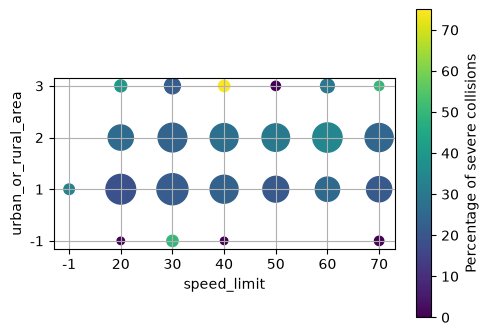

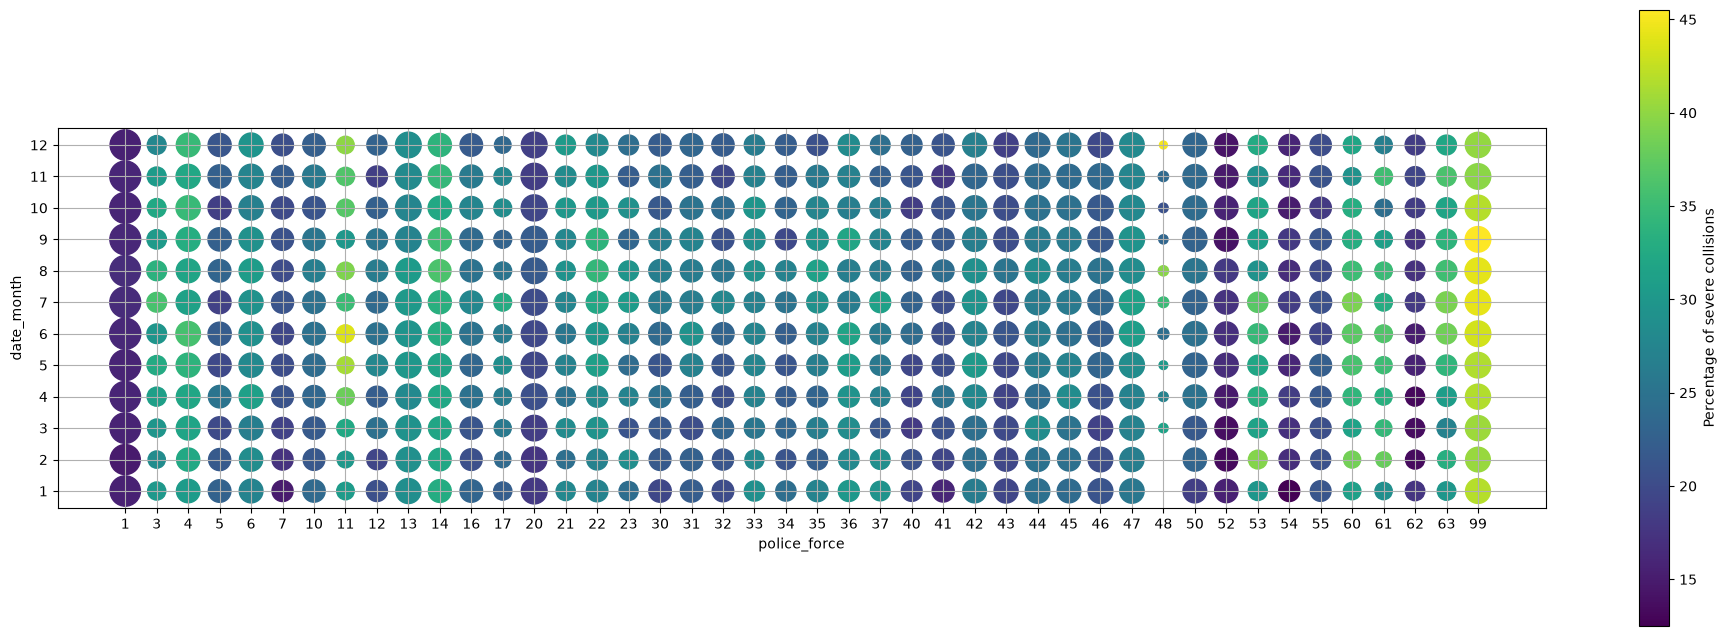

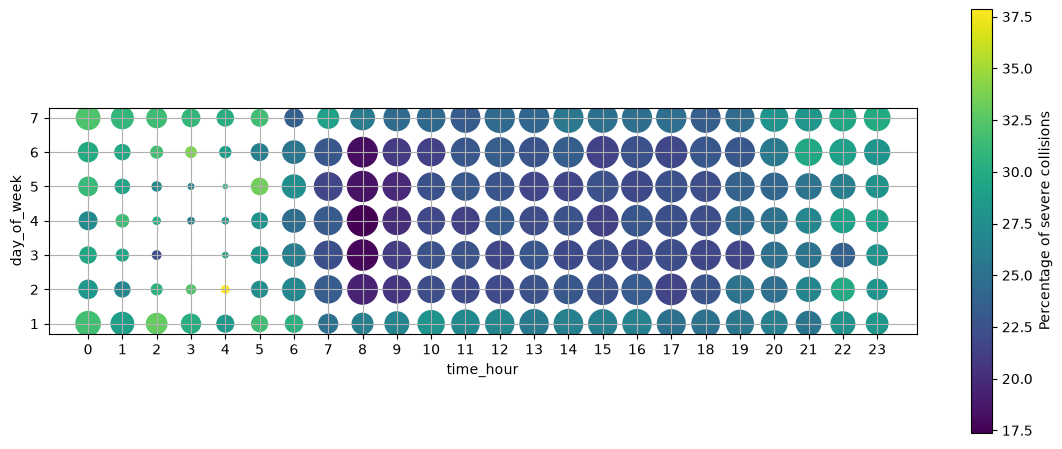

In [10]:
for_bivariate_graphing = [("light_conditions", "weather_conditions"), ("date_month", "weather_conditions"),
                           ("speed_limit", "road_type"), ("speed_limit", "urban_or_rural_area"), 
                           ("police_force", "date_month"), ("time_hour", "day_of_week")]

for x in for_bivariate_graphing:
    graph_bivariate(*x)

### Vehicle data

#### Vehicle type

In [11]:
collision_vehicle_df = collision_df

In [12]:
vehicle_df["vehicle_type"].value_counts()

vehicle_type
 9     514469
 1      64465
 19     47754
 3      36919
 5      18035
 11     12077
 8      11748
 21     10614
 4       7798
 33      5432
 90      4324
 2       4195
 98      3247
 20      3162
 97      2352
 17      1580
 23      1300
 22      1282
 10      1210
-1        652
 99       332
 16       289
 18        81
Name: count, dtype: int64

#### This shows that the most common vehicles, apart from cars, are bicycles, motorcycles, vans/trucks and busses, so their presence will be used as features.

In [13]:
collision_vehicle_df = pd.merge(collision_vehicle_df, 
                                (vehicle_df["vehicle_type"] == 1).groupby(vehicle_df["collision_index"]).any().rename("has_pedal_cycle").astype("int8"),
                                how="left", on="collision_index")
collision_vehicle_df["has_pedal_cycle"] = collision_vehicle_df["has_pedal_cycle"].fillna(-1)

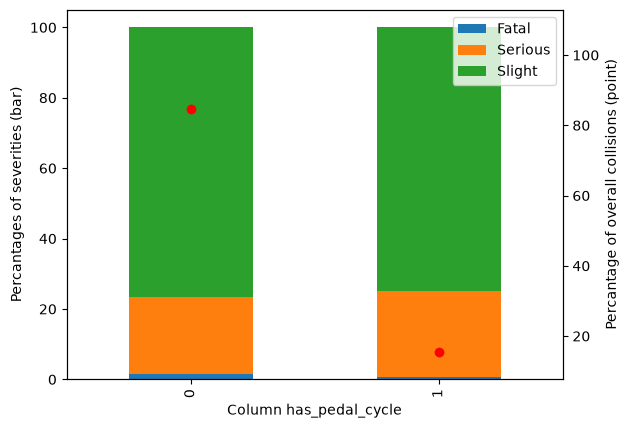

In [14]:
graph_severity_wrt_categorical_column("has_pedal_cycle", df_name="collision_vehicle_df")

#### This graph alone looks disaponting as the presence of a pedal cycle appears to have no relevance on severity, but it still can provide information with more context on the collision such as the speed limit etc.

#### Vehicle data is restricted to has/has not just for graphing purposes here, value counts will be used in the final features.

In [15]:
more_vehicle_type_columns = [(vehicle_df["vehicle_type"].isin([2,3,4,5])).groupby(vehicle_df["collision_index"]).any().rename("has_motorcycle").astype("int8"),
                         (vehicle_df["vehicle_type"].isin([20,21])).groupby(vehicle_df["collision_index"]).any().rename("has_heavy_goods").astype("int8"),
                         (vehicle_df["vehicle_type"] == 19).groupby(vehicle_df["collision_index"]).any().rename("has_van").astype("int8")]

for column in more_vehicle_type_columns:
    collision_vehicle_df = pd.merge(collision_vehicle_df, column,
                        how="left", on="collision_index")
    
collision_vehicle_df[["has_motorcycle", "has_heavy_goods", "has_van"]] = collision_vehicle_df[["has_motorcycle", "has_heavy_goods", "has_van"]].fillna(-1)

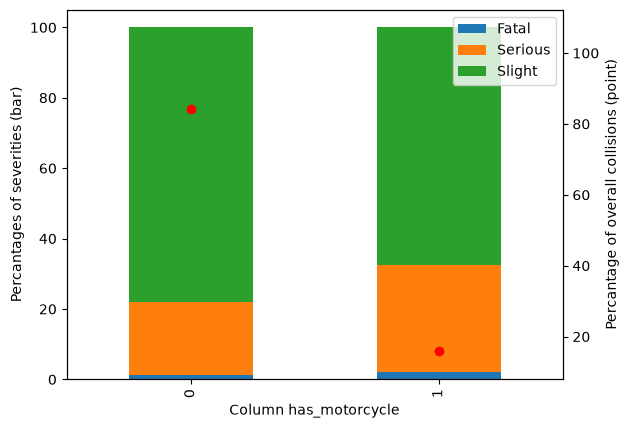

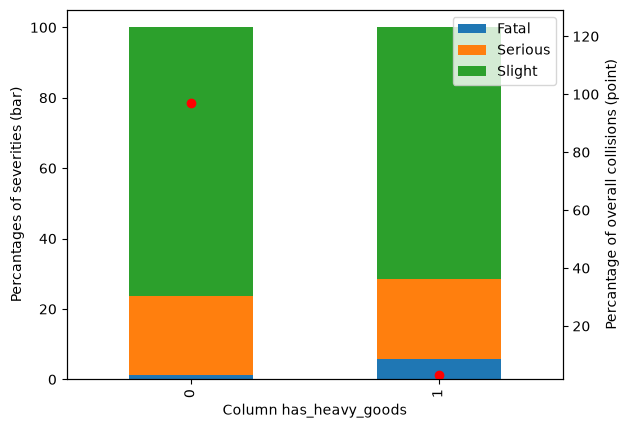

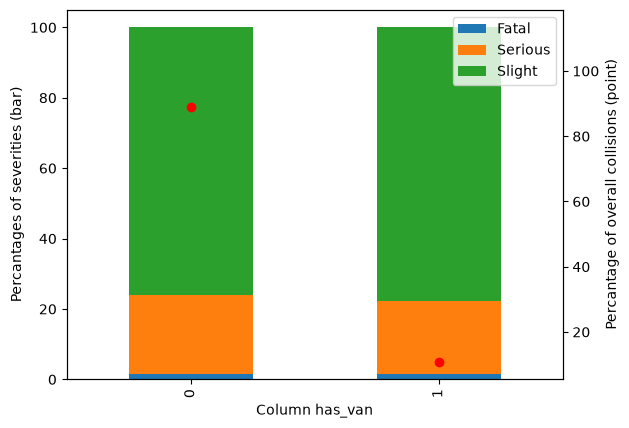

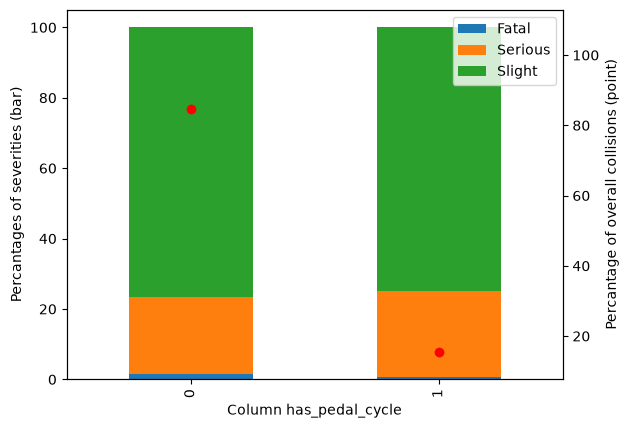

In [16]:
vehicle_type_column_names = ["has_motorcycle", "has_heavy_goods", "has_van", "has_pedal_cycle"]

for column in vehicle_type_column_names:
    graph_severity_wrt_categorical_column(column, df_name="collision_vehicle_df")

#### Other vehicle data columns

In [17]:
vehicle_circumstances_columns = [vehicle_df["skidding_and_overturning"].groupby(vehicle_df["collision_index"]).max().clip(upper=1).rename("has_skidding_overturning").astype("int8"),
                         vehicle_df["hit_object_in_carriageway"].groupby(vehicle_df["collision_index"]).max().clip(upper=1).rename("hit_in_carriageway").astype("int8"),
                         vehicle_df["hit_object_off_carriageway"].groupby(vehicle_df["collision_index"]).max().clip(upper=1).rename("hit_off_carriageway").astype("int8"),
                         vehicle_df["vehicle_leaving_carriageway"].groupby(vehicle_df["collision_index"]).max().clip(upper=1).rename("left_carriageway").astype("int8")]

for column in vehicle_circumstances_columns:
    collision_vehicle_df = pd.merge(collision_vehicle_df, column,
                        how="left", on="collision_index")

collision_vehicle_df[["has_skidding_overturning", "hit_in_carriageway", "hit_off_carriageway", "left_carriageway"]] = collision_vehicle_df[["has_skidding_overturning", "hit_in_carriageway", "hit_off_carriageway", "left_carriageway"]].fillna(-1)

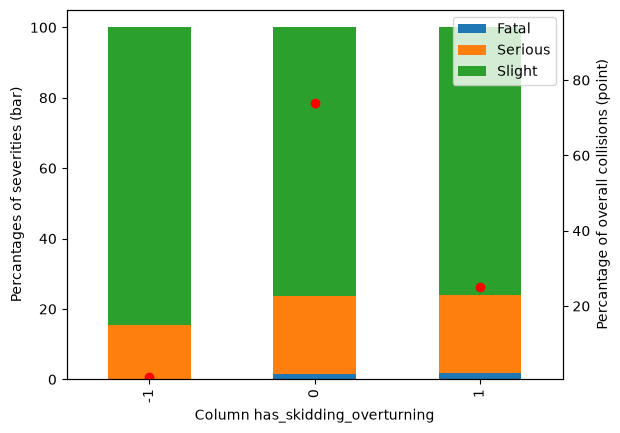

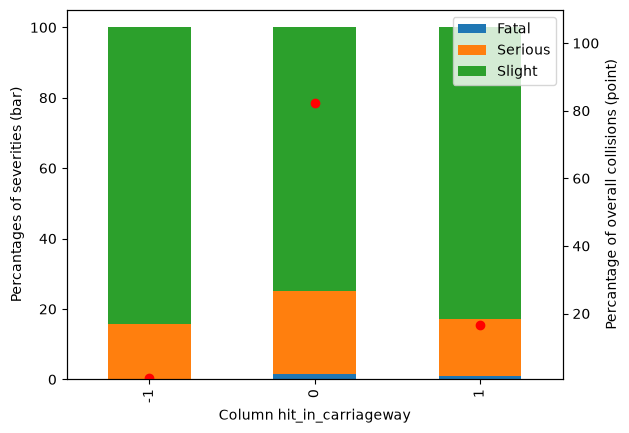

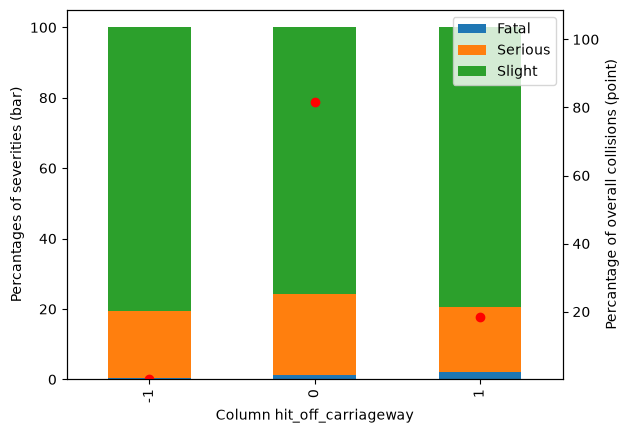

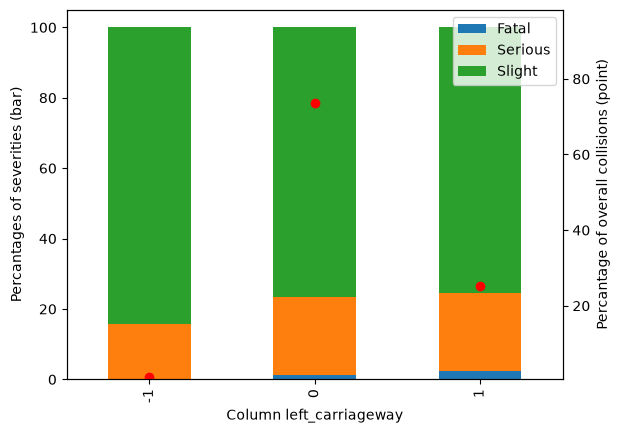

In [18]:
vehicle_circumstances_column_names = ["has_skidding_overturning", "hit_in_carriageway", "hit_off_carriageway", "left_carriageway"]

for column in vehicle_circumstances_column_names:
    graph_severity_wrt_categorical_column(column, df_name="collision_vehicle_df")

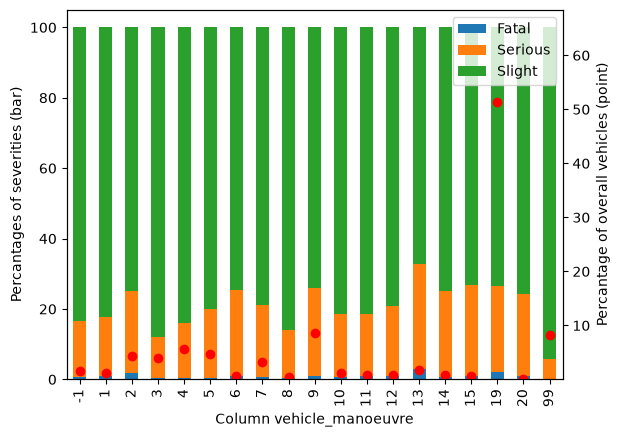

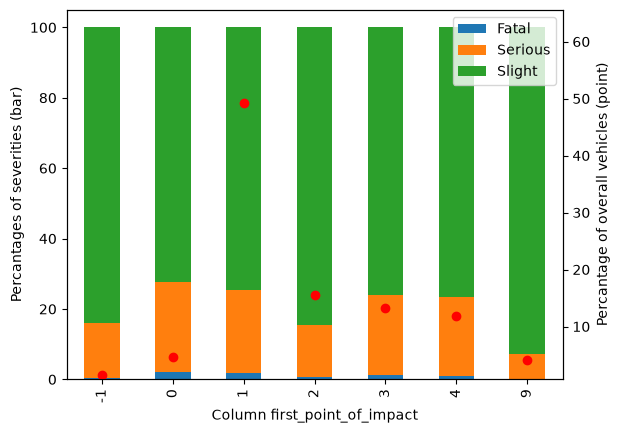

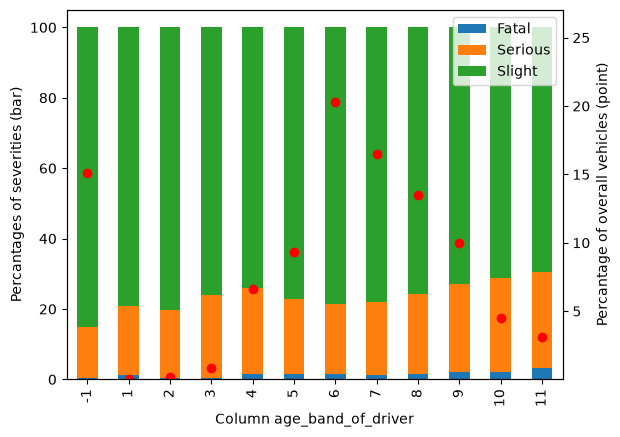

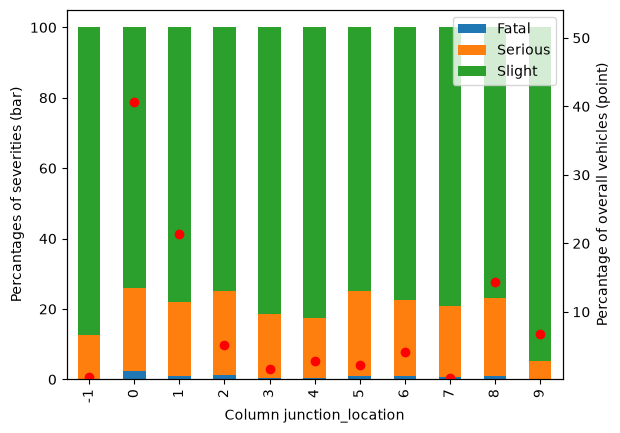

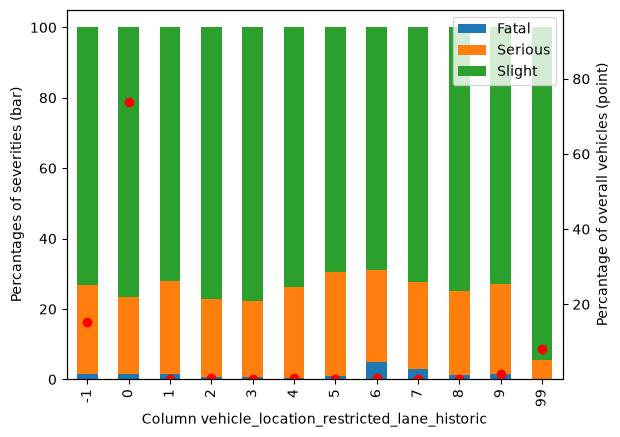

In [19]:
vehicle_data_with_severity = pd.merge(collision_df[["collision_index", "collision_severity"]], vehicle_df, how="right", on="collision_index")

vehicle_circumstances_not_binary_column_names = ["vehicle_manoeuvre", "first_point_of_impact", 
                                                 "age_band_of_driver", "junction_location", 
                                                 "vehicle_location_restricted_lane_historic"]
    
for column in vehicle_circumstances_not_binary_column_names:
    graph_severity_wrt_categorical_column(column, df_name="vehicle_data_with_severity", vehicle_view=True)

#### Note that the previous three graphs were plotted for datapoints corresponding to unique vehicles, not collisions.

### Influence of missing features

#### So far the next features are considered to be used in the final training data, however the presence of missing values in them might be causing leakage, so we should adress wether this is important (more severe collisions will have a tendency to be more closely documented and thus less missing values could be associated to them).

In [20]:
def check_missing_value_importance(collision_column_names, vehicle_column_names):
    collision_df = globals()["collision_df"]
    vehicle_df = globals()["vehicle_data_with_severity"]

    collisions_percentage_of_severe = round(collision_df[collision_df["collision_severity"].isin([1,2])].shape[0] / collision_df.shape[0], 5)
    vehicles_percentage_of_severe = round(vehicle_df[vehicle_df["collision_severity"].isin([1,2])].shape[0] / vehicle_df.shape[0], 5)

    print(f"Overall severe rate in collision df: {collisions_percentage_of_severe}")
    print(f"Overall severe rate in vehicle df: {vehicles_percentage_of_severe}")
    print("Overall severe rate − severe rate when missing, percentage of missing values: ")

    print("\nCOLLISION DF\n")

    for column in collision_column_names:
        s = collision_df[(collision_df[column] == -1)].shape[0]
        if s==0:
            print(column + "\n no missing values")
        else:
            percentage_of_severe_with_column_missing = round(collision_df[(collision_df["collision_severity"].isin([1, 2])) & (collision_df[column] == -1)].shape[0] / s - collisions_percentage_of_severe, 5)
            print(column + f"\n {percentage_of_severe_with_column_missing}, {round(s / collision_df.shape[0], 5)}")

    print("\nVEHICLE DF\n")

    for column in vehicle_column_names:
            s = vehicle_df[(vehicle_df[column] == -1)].shape[0]
            if s==0:
                print(column + "\n no missing values")
            else:
                percentage_of_severe_with_column_missing = round(vehicle_df[(vehicle_df["collision_severity"].isin([1, 2])) & (vehicle_df[column] == -1)].shape[0] / s - vehicles_percentage_of_severe, 5)
                print(column + f"\n {percentage_of_severe_with_column_missing}, {round(s / collision_df.shape[0], 5)}")
    



In [21]:
collision_columns_checked_for_missing_value_importance = ["police_force", "date_month", "time_hour", "first_road_class", 
                                                          "road_type", "speed_limit", "junction_detail", "junction_control",
                                                          "second_road_class", "light_conditions", "weather_conditions", 
                                                          "road_surface_conditions", "urban_or_rural_area"]

vehicle_columns_checked_for_missing_value_importance = ["vehicle_type", "skidding_and_overturning", "hit_object_in_carriageway",
                   "hit_object_off_carriageway", "vehicle_leaving_carriageway", 
                   "vehicle_manoeuvre", "first_point_of_impact", "age_band_of_driver", ]

check_missing_value_importance(collision_columns_checked_for_missing_value_importance, vehicle_columns_checked_for_missing_value_importance)

Overall severe rate in collision df: 0.23703
Overall severe rate in vehicle df: 0.22605
Overall severe rate − severe rate when missing, percentage of missing values: 

COLLISION DF

police_force
 no missing values
date_month
 no missing values
time_hour
 no missing values
first_road_class
 no missing values
road_type
 no missing values
speed_limit
 0.0963, 1e-05
junction_detail
 -0.13154, 0.03221
junction_control
 0.03217, 0.42062
second_road_class
 0.06635, 0.02764
light_conditions
 0.0963, 4e-05
weather_conditions
 -0.07036, 3e-05
road_surface_conditions
 -0.12089, 0.00702
urban_or_rural_area
 0.01297, 2e-05

VEHICLE DF

vehicle_type
 0.00708, 0.00158
skidding_and_overturning
 -0.07792, 0.02288
hit_object_in_carriageway
 -0.077, 0.02277
hit_object_off_carriageway
 -0.05957, 0.0044
vehicle_leaving_carriageway
 -0.07742, 0.02298
vehicle_manoeuvre
 -0.06124, 0.02827
first_point_of_impact
 -0.06577, 0.02627
age_band_of_driver
 -0.07682, 0.27646


#### Unfortunately, this analysis revealed that the missing data does in some cases corelate with the severity of collisions. Due to this, columns junction_control from collision_df and age_band_of_driver from vehicle_df will be removed. 

#### Furthermore features junction_detail, second_road_class, road_surface_conditions from collision_df and skidding_and_overturning, hit_object_in_carriageway, hit_object_off_carriageway, vehicle_leaving_carriageway, vehicle_manoeuvre and first_point_of_impact from vehicle_df still correlate, but the percentage of their missing values small enough.

#### For the resulting models to be interpretable as predictors of collision severity from information available shortly after the collision, missing values in all columns will be imputed to match the most frequent category.